# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 15   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 15: Bombay, Sphynx, american_bulldog, boxer
  Скачиваю https://github.com/ykvnkm/computer-vision-course/releases/download/data-v1/variant_15.zip
  variant_15.zip: 77.3 МБ, готово.                              
  Распаковываю в /content/data/variant_15 ...
Готово: /content/data/variant_15 (800 изображений)
данные варианта: /content/data/variant_15
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 5.0.0 | numpy 2.1.3 | pandas 2.2.3


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [3]:
# TODO: прочитайте variant.json и напечатайте его.
# Подсказка: путь собирайте от DATA_DIR, это объект Path, а не строка:
#   (DATA_DIR / "variant.json").read_text(encoding="utf-8") даёт текст файла,
#   json.loads(...) превращает текст в словарь.
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(variant_info)

# TODO: прочитайте labels.csv в DataFrame labels и покажите первые строки.
# Путь к файлу: DATA_DIR / "labels.csv"
labels = pd.read_csv(DATA_DIR / "labels.csv")
labels.head()


{'variant': 15, 'dataset_version': 'v1', 'source': 'release', 'breeds': ['Bombay', 'Sphynx', 'american_bulldog', 'boxer'], 'species': {'Bombay': 'cat', 'Sphynx': 'cat', 'american_bulldog': 'dog', 'boxer': 'dog'}, 'class_ids': {'Bombay': 0, 'Sphynx': 1, 'american_bulldog': 2, 'boxer': 3}, 'names_ru': {'Bombay': 'бомбейская кошка', 'Sphynx': 'сфинкс', 'american_bulldog': 'американский бульдог', 'boxer': 'боксёр'}, 'n_images': 800, 'n_boxes': 400, 'n_trimaps': 800, 'per_breed': {'Bombay': {'images': 200, 'boxes': 100, 'trimaps': 200}, 'Sphynx': {'images': 200, 'boxes': 100, 'trimaps': 200}, 'american_bulldog': {'images': 200, 'boxes': 100, 'trimaps': 200}, 'boxer': {'images': 200, 'boxes': 100, 'trimaps': 200}}, 'dataset': 'Oxford-IIIT Pet', 'dataset_url': 'https://www.robots.ox.ac.uk/~vgg/data/pets/', 'license': 'CC BY-SA 4.0', 'citation': 'O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V. Jawahar. Cats and Dogs. IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 2012.'}


,filename,breed,species,class_id
0,american_bulldog_2.jpg,american_bulldog,dog,2
1,american_bulldog_3.jpg,american_bulldog,dog,2
2,american_bulldog_5.jpg,american_bulldog,dog,2
3,american_bulldog_6.jpg,american_bulldog,dog,2
4,american_bulldog_7.jpg,american_bulldog,dog,2


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [4]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

# TODO: прочитайте файл через cv2.imread(str(example_path)) в переменную bgr
# TODO: напечатайте type, shape, dtype, min, max и значение пикселя в центре кадра
#       bgr[bgr.shape[0] // 2, bgr.shape[1] // 2]
bgr = cv2.imread(str(example_path))
h, w = bgr.shape[:2]
print(type(bgr), bgr.shape, bgr.dtype, bgr.min(), bgr.max())
print("пиксель в центре (B, G, R):", bgr[h // 2, w // 2])

Sphynx_5.jpg
<class 'numpy.ndarray'> (390, 600, 3) uint8 0 255
пиксель в центре (B, G, R): [ 74  82 135]


пиксель в центре (R, G, B): [135  82  74]


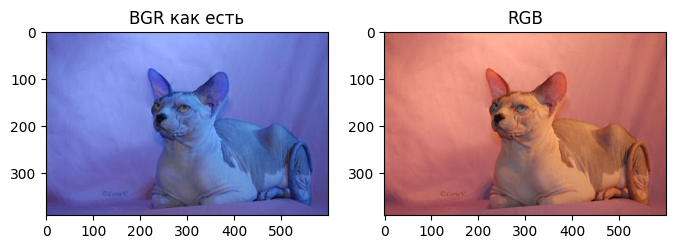

In [5]:
# TODO: переведите bgr в rgb через cv2.cvtColor(..., cv2.COLOR_BGR2RGB)
# TODO: покажите bgr и rgb рядом. Что случилось с цветами?
#   plt.subplot(1, 2, 1); plt.imshow(bgr)
#   plt.subplot(1, 2, 2); plt.imshow(rgb)
#   plt.show()
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
print("пиксель в центре (R, G, B):", rgb[h // 2, w // 2])

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(bgr); plt.title("BGR как есть")
plt.subplot(1, 2, 2); plt.imshow(rgb); plt.title("RGB")
plt.show()

Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [6]:
# TODO: получите gray, resized (224x224) и flipped, напечатайте их shape
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)
print("gray:", gray.shape, "| resized:", resized.shape, "| flipped:", flipped.shape)

gray: (390, 600) | resized: (224, 224, 3) | flipped: (390, 600, 3)


In [7]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


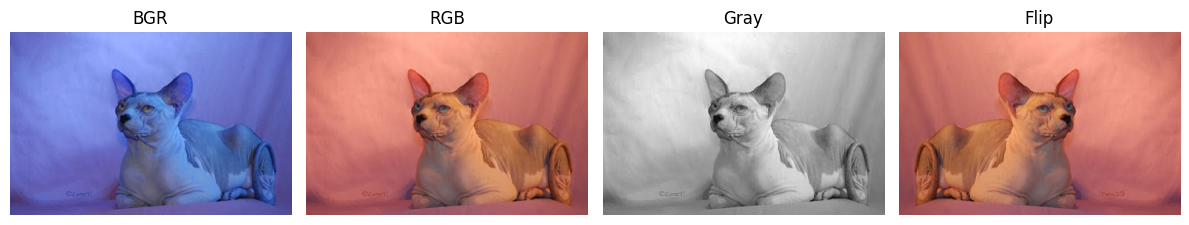

In [8]:
# TODO: 4 панели на одной фигуре: BGR как есть, RGB, серое, отражение
#   plt.figure(figsize=(12, 3))
#   plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR")
#   ... так же для rgb, gray (cmap="gray") и flipped
#   plt.savefig(RESULTS / "transforms.png", dpi=110)

plt.figure(figsize=(12, 3))
plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR"); plt.axis("off")
plt.subplot(1, 4, 2); plt.imshow(rgb); plt.title("RGB"); plt.axis("off")
plt.subplot(1, 4, 3); plt.imshow(gray, cmap="gray"); plt.title("Gray"); plt.axis("off")
plt.subplot(1, 4, 4); plt.imshow(flipped); plt.title("Flip"); plt.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [9]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    # TODO: через Image.open(p) запишите pil_format, mode, width, height
    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"], rec["height"] = im.size
    # TODO: has_xml: существует ли XML_DIR / (p.stem + ".xml")
    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()
    # TODO: breed и species из label_by_file.loc[p.name]
    row = label_by_file.loc[p.name]
    rec["breed"] = row["breed"]
    rec["species"] = row["species"]
    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Bombay_1.jpg,.jpg,JPEG,RGB,183,275,True,Bombay,cat
1,Bombay_10.jpg,.jpg,JPEG,RGB,500,375,True,Bombay,cat
2,Bombay_100.jpg,.jpg,JPEG,RGB,300,284,True,Bombay,cat
3,Bombay_101.jpg,.jpg,JPEG,RGB,450,320,True,Bombay,cat
4,Bombay_102.jpg,.jpg,JPEG,RGB,300,225,True,Bombay,cat


In [10]:
# TODO: соберите словарь summary с главными числами и сохраните в results/summary.csv
# Минимум: число файлов, пород, кошек и собак, min/медиана/max ширины и высоты,
# сколько не RGB, сколько .jpg на самом деле не JPEG, сколько с XML.
fake_jpg = info["ext"].isin([".jpg", ".jpeg"]) & (info["pil_format"] != "JPEG")

summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
}
for sp, c in info["species"].value_counts().items():   # кошки и собаки, не гадаем с названиями
    summary[f"n_{sp}"] = int(c)
summary.update({
    "width_min": int(info["width"].min()),
    "width_median": float(info["width"].median()),
    "width_max": int(info["width"].max()),
    "height_min": int(info["height"].min()),
    "height_median": float(info["height"].median()),
    "height_max": int(info["height"].max()),
    "n_not_rgb": int((info["mode"] != "RGB").sum()),
    "n_fake_jpg": int(fake_jpg.sum()),
    "n_with_xml": int(info["has_xml"].sum()),
})
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,15.0
1,n_files,800.0
2,n_breeds,4.0
3,n_cat,400.0
4,n_dog,400.0
5,width_min,114.0
6,width_median,500.0
7,width_max,1725.0
8,height_min,103.0
9,height_median,375.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [14]:
# TODO: напечатайте файлы с mode != "RGB" и файлы с pil_format != "JPEG"
not_rgb = info[info["mode"] != "RGB"]
print("Не RGB:", len(not_rgb))
print(not_rgb[["filename", "pil_format", "mode"]].to_string(index=False))

fake = info[fake_jpg]
print("\n.jpg, но не JPEG:", len(fake))
print(fake[["filename", "pil_format", "mode"]].to_string(index=False))

Не RGB: 0
Empty DataFrame
Columns: [filename, pil_format, mode]
Index: []

.jpg, но не JPEG: 0
Empty DataFrame
Columns: [filename, pil_format, mode]
Index: []


In [15]:
# TODO: сравните формы массивов для одного проблемного файла
bad = pd.concat([not_rgb, fake]).drop_duplicates("filename")
if len(bad):
    bp = str(IMG_DIR / bad.iloc[0]["filename"])
    print(bad.iloc[0]["filename"], "| режим Pillow:", bad.iloc[0]["mode"])
    print("imread по умолчанию:", cv2.imread(bp).shape)
    print("IMREAD_UNCHANGED:   ", cv2.imread(bp, cv2.IMREAD_UNCHANGED).shape)
else:
    print("проблемных файлов нет")

проблемных файлов нет


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [17]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

# TODO: возьмите одно изображение с XML и напечатайте его боксы
# TODO: прочитайте его trimap: cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
#       и выведите np.unique(trimap)
sample = info[info["has_xml"]].iloc[0]
stem = Path(sample["filename"]).stem
print(sample["filename"], "боксы:", read_boxes(XML_DIR / (stem + ".xml")))

trimap = cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
print("trimap:", trimap.shape, "значения:", np.unique(trimap))

Bombay_1.jpg боксы: [(93, 43, 151, 99)]
trimap: (275, 183) значения: [1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

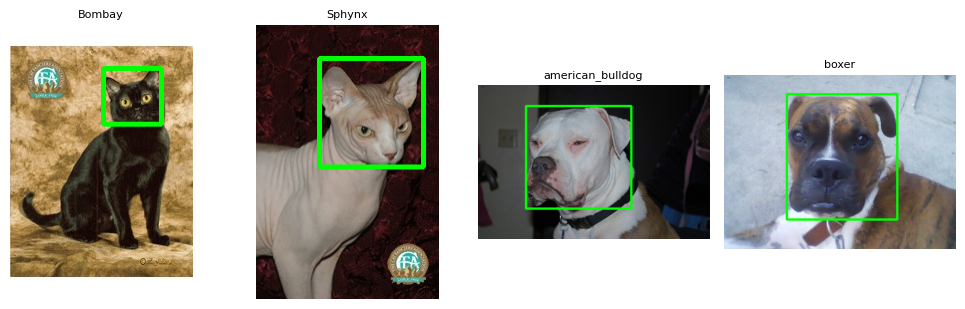

In [18]:
# TODO: для каждой породы возьмите одно фото с XML, нарисуйте бокс,
#       покажите все фото в один ряд через plt.subplot и сохраните в results/samples_grid.png
breeds = sorted(info["breed"].unique())
plt.figure(figsize=(2.5 * len(breeds), 3.2))
for i, b in enumerate(breeds, 1):
    cand = info[(info["breed"] == b) & info["has_xml"] & (info["mode"] == "RGB")]
    r = cand.iloc[0]
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / r["filename"])), cv2.COLOR_BGR2RGB)
    x0, y0, x1, y1 = read_boxes(XML_DIR / (Path(r["filename"]).stem + ".xml"))[0]
    cv2.rectangle(img, (x0, y0), (x1, y1), (0, 255, 0), 3)
    plt.subplot(1, len(breeds), i)
    plt.imshow(img); plt.title(b, fontsize=8); plt.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "samples_grid.png", dpi=110)
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [19]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

       metric  value
      variant   15.0
      n_files  800.0
     n_breeds    4.0
        n_cat  400.0
        n_dog  400.0
    width_min  114.0
 width_median  500.0
    width_max 1725.0
   height_min  103.0
height_median  375.0
   height_max 1600.0
    n_not_rgb    0.0
   n_fake_jpg    0.0
   n_with_xml  400.0
не хватает: ничего, все 3 файла на месте


In [20]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>